# Rossi-$\alpha$ Methods Benchmark: the cost of precision

Estimators of the prompt decay constant $\alpha$ for a subcritical U235–H2O sphere with an
external B10 detector, compared on **accuracy** and, above all, on **how many histories (and how
much wall-clock time) each one needs to reach the same statistical precision** — across an
8-point $k_{eff}$ grid (0.40–0.98) and a detector-distance scan.

| method | observable | pair/single scaling |
|---|---|---|
| **Point kinetics (PK)** | $\alpha=(k(1-\beta_{eff})-1)/(k\Lambda)$, from one IFP eigenvalue run | model — no detector histories |
| **Doubles (parent-ID)** | same-chain detection-pair $\Delta t$, chains tagged by `parent_id` | pairs, rate $\propto\varepsilon^2$ — *unphysical best case* |
| **Doubles (realistic)** | all pairs + accidental background at the optimal source rate | pairs, no chain oracle — the honest competitor |
| **ACDC** | $\sum_i F_i\!\int g_i(t)g_i(t{+}\tau)\,dt$ from per-cell sweeps | singles per cell, rate $\propto\varepsilon$ |
| **Pulsed die-away** | singles envelope $s(t)\sim e^{\alpha t}$ | singles — but needs a *pulsable* source |

**One convergence metric for every method.** $\sigma_\alpha$ is the *across-realization* standard
deviation: partition a run into disjoint, equal-size realizations (sphere → disjoint `parent_id`
ranges; sweep → disjoint `parent_id` ranges per cell, assembled across cells), fit $\alpha$ in
each, take the spread. No $\kappa_S$ fudge, no Poisson approximation — identical for all methods.
Chain bootstrap and the MLE Fisher error are kept only as cross-checks. The target is
$\sigma_\alpha \le 5\%\,|\alpha_{ref}|$, with $\alpha_{ref}$ the common high-statistics
consensus value.

Three foundations carried over: **(1)** OpenMC under-disperses fission multiplicity
($E[n(n{-}1)]\approx2.06$ vs physical 4.63), so ACDC uses the calibrated $M_{sim}=2.76$; $\alpha$
is unaffected. **(2)** $\alpha$ is the *late-time* fundamental-mode slope — every method is fit in
the same frozen window per $k$. **(3)** The realistic Doubles fit needs a flat background; the raw
pulsed all-pairs fit silently degenerates into the singles die-away.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from project.analysis import greens_loader as gl
from project.analysis import rossi_benchmark as rb

FIGURES_DIR = Path("../outputs/figures/benchmark")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS = rb.RESULTS_ROOT

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12, "legend.fontsize": 10,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.9, "lines.markersize": 6,
})

# 8-point k grid; original 4 also have 40M high-precision sweeps for the gate.
LABELS = ["098", "095", "090", "080", "070", "060", "050", "040"]
ANCHOR_LABELS = ["098", "090", "070", "040"]

# Method-centric style: color = method (not k) for every cost figure.
M = {
    "acdc":      dict(label="ACDC",                color="#1f77b4", marker="s"),
    "oracle":    dict(label="Doubles (parent-ID)", color="#d62728", marker="o"),
    "realistic": dict(label="Doubles (realistic)", color="#ff7f0e", marker="^"),
    "die":       dict(label="die-away*",           color="#2ca02c", marker="D"),
    "pk":        dict(label="point kinetics",      color="#7f7f7f", marker=None),
}
# per-k ramp kept only for the alignment-gate overlay
KCOL = {"098": "#08306b", "095": "#2171b5", "090": "#4292c6", "080": "#41ab5d",
        "070": "#ff7f0e", "060": "#e6550d", "050": "#d62728", "040": "#7a0177"}
MAXB = 25            # cap realizations per budget (stable sigma needs ~25-30)
TARGET = 0.05        # sigma_alpha / |alpha| target


def fmt_N(n):
    if n is None or not np.isfinite(n):
        return "—"
    for u, s in [(1e12, "T"), (1e9, "G"), (1e6, "M"), (1e3, "k")]:
        if abs(n) >= u:
            return f"{n/u:.1f}{s}"
    return f"{n:.0f}"


def fmt_t(s):
    if not np.isfinite(s):
        return "—"
    if s < 120:
        return f"{s:.0f} s"
    if s < 7200:
        return f"{s/60:.0f} min"
    if s < 1.728e5:
        return f"{s/3600:.1f} h"
    return f"{s/86400:.1f} d"

## 0. Estimator alignment at full statistics (acceptance gate)

Before any cost comparison: the model-based ACDC curve and the direct **Doubles (parent-ID)**
pair histogram must describe the *same* $R(\tau)$ on an absolute scale (this is what fixes
$M_{sim}$). Overlay of $R_{ACDC}(\tau)$ and the Doubles same-chain pair rate for the four
high-precision (40M sweep) $k$ values, clipped to the signal band.

k098: window pairs=  5680  scale=1.007  M_emp=2.92+/-0.11  alpha BF=   -352.4+/-  22.7  ACDC=   -378.4+/-   2.8  (1.14 sigma)
k090: window pairs=   155  scale=0.946  M_emp=2.57+/-0.14  alpha BF=  -1464.2+/- 163.1  ACDC=  -1467.5+/-   6.9  (0.02 sigma)
k070: window pairs=    21  scale=1.133  M_emp=2.75+/-0.29  alpha BF=  -3825.3+/-1200.6  ACDC=  -5053.9+/-  78.9  (1.02 sigma)
k040: window pairs=     5  scale=0.939  M_emp=2.92+/-0.47  alpha BF=  -3211.3+/-4826.0  ACDC= -10326.3+/- 411.6  (1.47 sigma)


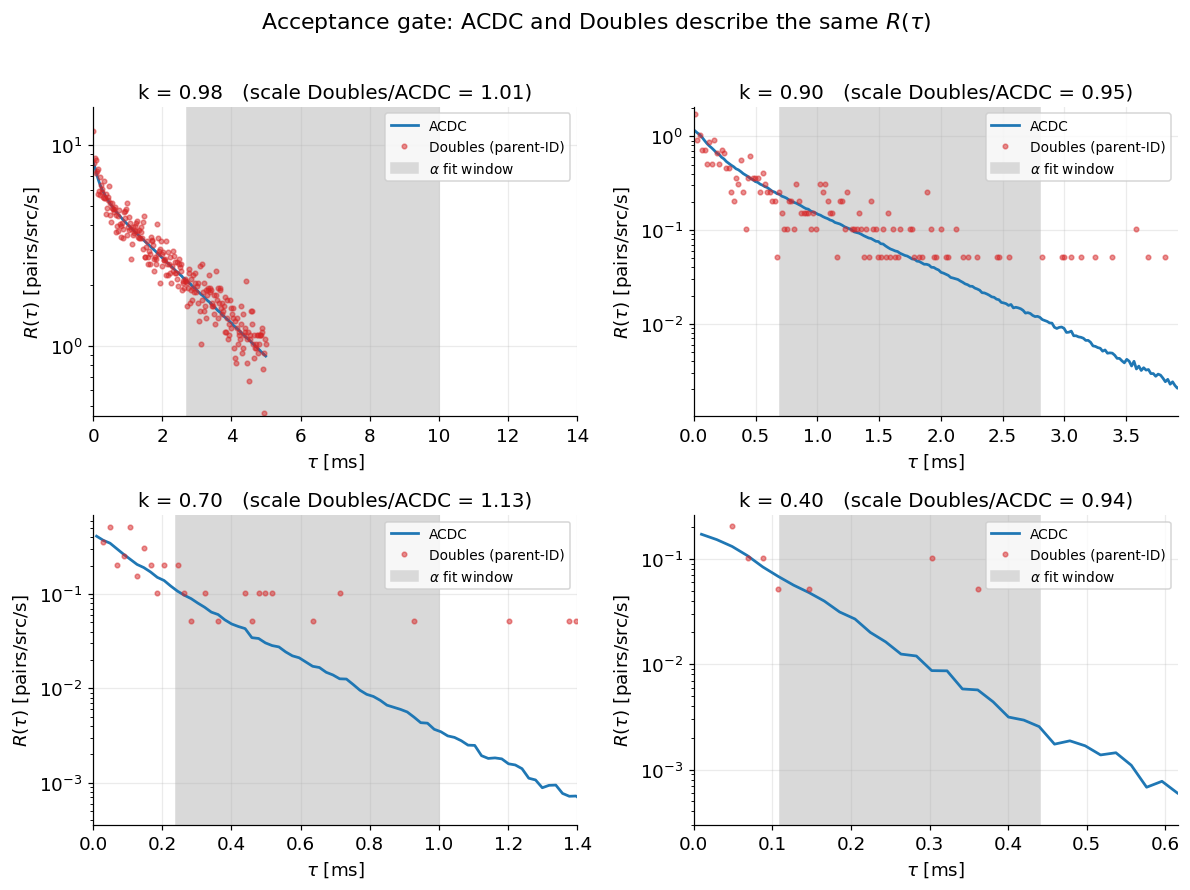

In [2]:
gate = {L: rb.alignment_gate(L, verbose=True) for L in ANCHOR_LABELS}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, L in zip(axes.flat, ANCHOR_LABELS):
    r = gate[L]
    tau_ms = r["tau"] * 1e3
    lo, hi = rb.FIT_WINDOWS[L]
    inwin = (r["tau"] >= 2 * rb.DT) & (r["tau"] <= 1.4 * hi)
    ypos = r["R_acdc"][inwin]; ypos = ypos[ypos > 0]
    m = r["R_acdc"] > 0
    ax.semilogy(tau_ms[m], r["R_acdc"][m], "-", color=M["acdc"]["color"], lw=1.8, label="ACDC")
    nz = r["R_bf"] > 0
    ax.semilogy(tau_ms[nz], r["R_bf"][nz], "o", ms=3, color=M["oracle"]["color"], alpha=0.5,
                label="Doubles (parent-ID)")
    ax.axvspan(lo * 1e3, hi * 1e3, color="0.85", zorder=0, label=r"$\alpha$ fit window")
    ax.set_xlim(0, 1.4 * hi * 1e3); ax.set_ylim(ypos.min() * 0.5, ypos.max() * 2)
    ax.set_title(f"k = {int(L)/100:.2f}   (scale Doubles/ACDC = {r['scale_bf_over_acdc']:.2f})")
    ax.set_xlabel(r"$\tau$ [ms]"); ax.set_ylabel(r"$R(\tau)$ [pairs/src/s]")
    ax.legend(fontsize=9)
fig.suptitle("Acceptance gate: ACDC and Doubles describe the same $R(\\tau)$", y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "alignment_gate.png")
plt.show()

## 1. They agree where measurable — then the cost diverges

Context for everything below: at a uniform 1M-history budget, every method that *can* measure
returns the same $\alpha(k)$ (left); PK peels away below $k\approx0.9$ where the one-point model
loses the spatial physics (right). The Doubles markers simply stop existing at low $k$ — that
absence is the result. The rest of the notebook quantifies the **cost** behind these markers.

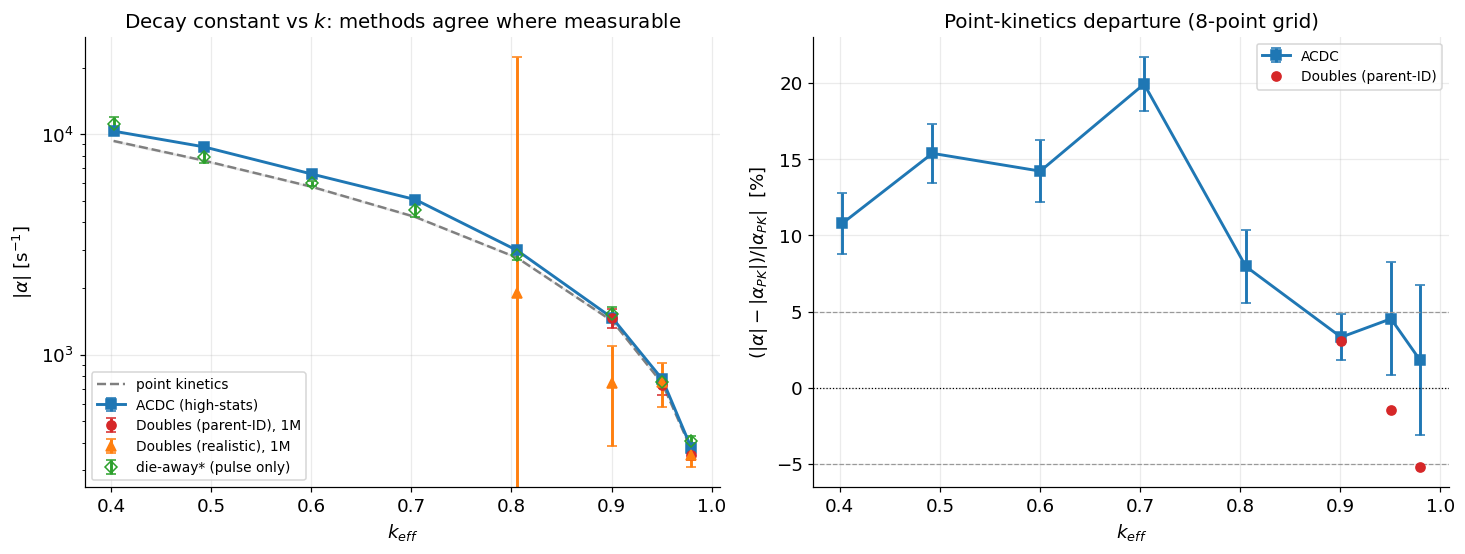

In [3]:
bench = pd.DataFrame([rb.benchmark_row(L, n_boot=20, rng=20 + i) for i, L in enumerate(LABELS)])
bench = bench.sort_values("k").reset_index(drop=True)

# high-stats ACDC truth per k (for the PK-departure systematic)
acdc_best = {L: rb.acdc_alpha_sigma(L) for L in LABELS}
bench["acdc_hi"] = [acdc_best[L][0] for L in bench["label"]]
bench["acdc_hi_err"] = [acdc_best[L][1] for L in bench["label"]]
kk = bench["k"].to_numpy()

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13.5, 5.2))
axA.plot(kk, np.abs(bench["pk"]), "--", color=M["pk"]["color"], lw=1.6, label=M["pk"]["label"])
axA.fill_between(kk, np.abs(bench["pk"]) - bench["pk_err"], np.abs(bench["pk"]) + bench["pk_err"],
                 color=M["pk"]["color"], alpha=0.12)
axA.errorbar(kk, np.abs(bench["acdc_hi"]), yerr=bench["acdc_hi_err"], fmt="s-",
             color=M["acdc"]["color"], capsize=3, label="ACDC (high-stats)")
ok_o = ~bench["bf_oracle_cens"]
axA.errorbar(kk[ok_o], np.abs(bench["bf_oracle"][ok_o]), yerr=bench["bf_oracle_err"][ok_o],
             fmt="o", color=M["oracle"]["color"], capsize=3, label="Doubles (parent-ID), 1M")
ok_r = ~bench["bf_real_cens"]
axA.errorbar(kk[ok_r], np.abs(bench["bf_real"][ok_r]), yerr=bench["bf_real_err"][ok_r],
             fmt="^", color=M["realistic"]["color"], capsize=3, label="Doubles (realistic), 1M")
axA.errorbar(kk, np.abs(bench["die"]), yerr=bench["die_err"], fmt="D", color=M["die"]["color"],
             mfc="none", capsize=3, label="die-away* (pulse only)")
axA.set_yscale("log"); axA.set_xlabel(r"$k_{eff}$"); axA.set_ylabel(r"$|\alpha|$ [s$^{-1}$]")
axA.set_title("Decay constant vs $k$: methods agree where measurable"); axA.legend(fontsize=9)

dep = (np.abs(bench["acdc_hi"]) - np.abs(bench["pk"])) / np.abs(bench["pk"])
dep_err = bench["acdc_hi_err"] / np.abs(bench["pk"])
axB.errorbar(kk, 100 * dep, yerr=100 * dep_err, fmt="s-", color=M["acdc"]["color"], capsize=3,
             label="ACDC")
dep_o = (np.abs(bench["bf_oracle"][ok_o]) - np.abs(bench["pk"][ok_o])) / np.abs(bench["pk"][ok_o])
axB.errorbar(kk[ok_o], 100 * dep_o, fmt="o", color=M["oracle"]["color"], capsize=3,
             label="Doubles (parent-ID)")
axB.axhline(0, color="k", lw=0.8, ls=":")
axB.axhline(5, color="0.6", lw=0.8, ls="--"); axB.axhline(-5, color="0.6", lw=0.8, ls="--")
axB.set_xlabel(r"$k_{eff}$"); axB.set_ylabel(r"$(|\alpha|-|\alpha_{PK}|)/|\alpha_{PK}|$  [%]")
axB.set_title("Point-kinetics departure (8-point grid)"); axB.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "methods_vs_k.png")
plt.show()

## 2. The master curve — $\sigma_\alpha$ vs total histories (flagship $k=0.90$)

The headline. A matched **10M-history** sphere run (Doubles) and per-cell sweep (ACDC, total =
per-cell × $n_{cells}$, so the budgets are *fair*) at $k=0.90$, gap 10 cm. For each method we
measure $\sigma_\alpha$ at a ladder of budgets from disjoint realizations, then **validate the
$\sigma\propto N^{-1/2}$ slope** before sliding down that line to the 5% target.

* Read **horizontally** at the dotted 5% line → histories each method needs.
* Read **vertically** at any budget → precision at equal cost.
* The **horizontal gap** between two curves → "X times more histories".

Solid = measured; dashed = $N^{-1/2}$ extrapolation (only drawn where the slope was validated);
the large marker on the 5% line is the histories-to-target.

In [4]:
FL = rb.FLAGSHIP_LABEL
win = rb.FIT_WINDOWS[FL]

# matched 10M flagship data
df10 = rb.load_chain_events_from(rb.FLAGSHIP_DOUBLES_TRACK)          # sphere doubles events
n_sphere = int(df10["parent_id"].max())
events10, n_cell10 = rb.load_sweep_events(rb.FLAGSHIP_SWEEP_EVENTS)  # per-cell sweep events
n_cells = len(events10)
n_sweep_total = n_cell10 * n_cells
F10 = rb.fission_coarse_from_dir(RESULTS / f"greens-function-k{FL}-bench10M", 8, 10)
alpha_ref = rb.reference_alpha(FL, rb.FLAGSHIP_SWEEP_EVENTS)

bud_sp = rb.budget_ladder(n_sphere)
bud_sw = rb.budget_ladder(n_sweep_total)
print(f"flagship k={gl.K_OF_LABEL[FL]:.2f}: sphere {n_sphere:,} histories, "
      f"sweep {n_sweep_total:,} ({n_cell10:,}/cell x {n_cells}); |alpha_ref|={abs(alpha_ref):.0f}")

curves = {}
curves["oracle"] = rb.sigma_vs_budget(
    lambda n: rb.oracle_block_alphas(df10, n, n_sphere, win, max_blocks=MAXB), bud_sp, n_sphere)
curves["realistic"] = rb.sigma_vs_budget(
    lambda n: rb.realistic_block_alphas(df10, n, n_sphere, win, rng=1, max_blocks=MAXB),
    bud_sp, n_sphere)
curves["die"] = rb.sigma_vs_budget(
    lambda n: rb.die_block_alphas(df10, n, n_sphere, win, max_blocks=MAXB), bud_sp, n_sphere)
curves["acdc"] = rb.sigma_vs_budget(
    lambda n: rb.acdc_block_alphas(events10, F10, n, n_cell10, win, n_cells=n_cells, max_blocks=MAXB),
    bud_sw, n_sweep_total)

scaling = {m: rb.fit_sigma_scaling(c) for m, c in curves.items()}
h2t = {m: rb.histories_to_target(curves[m], alpha_ref, TARGET, scaling[m]) for m in curves}
for m in curves:
    print(f"{M[m]['label']:22s} slope={scaling[m]['slope']:+.2f} "
          f"(ok={scaling[m]['slope_ok']})  N->5%={fmt_N(h2t[m]['n_target'])}")

flagship k=0.90: sphere 9,999,904 histories, sweep 10,000,000 (125,000/cell x 80); |alpha_ref|=1584


/home/itay/projects/initiation-project/project/analysis/rossi_benchmark.py:251: RuntimeWarning: divide by zero encountered in log1p
  np.log1p(-w) + log_truncexp(alpha),


Doubles (parent-ID)    slope=-0.55 (ok=True)  N->5%=8.5M
Doubles (realistic)    slope=-0.54 (ok=True)  N->5%=54.0M
die-away*              slope=-0.41 (ok=True)  N->5%=1.2M
ACDC                   slope=-0.61 (ok=True)  N->5%=3.1M


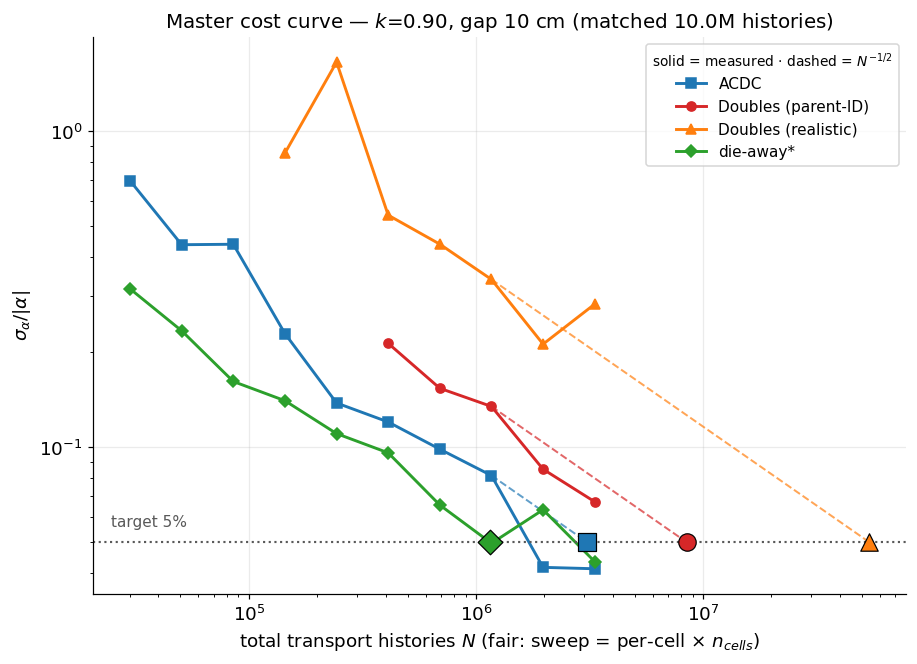

histories to sigma=5%|alpha| @ k=0.90:
  ACDC: 3.1M  ·  Doubles (parent-ID): 8.5M  ·  Doubles (realistic): 54.0M  ·  die-away*: 1.2M
  -> Doubles (parent-ID) needs 3x ACDC's histories


In [5]:
fig, ax = plt.subplots(figsize=(8.5, 6.2))
for m in ["acdc", "oracle", "realistic", "die"]:
    c = curves[m]; meta = M[m]
    d = c[c["sigma"].notna() & (c["sigma"] > 0)]
    if len(d):
        ax.loglog(d["n_prime"], d["sigma"] / abs(alpha_ref), marker=meta["marker"],
                  color=meta["color"], label=meta["label"])
    h = h2t[m]
    if h["ok"] and np.isfinite(h["n_target"]) and len(d):
        Nx = np.array([h["anchor_N"], h["n_target"]])
        Sx = h["anchor_sigma"] / abs(alpha_ref) * np.sqrt(h["anchor_N"] / Nx)
        ax.loglog(Nx, Sx, ls="--", color=meta["color"], lw=1.3, alpha=0.7)
        ax.scatter([h["n_target"]], [TARGET], marker=meta["marker"], color=meta["color"],
                   s=130, zorder=6, edgecolor="k", linewidth=0.8)
ax.axhline(TARGET, color="0.35", ls=":", lw=1.4)
ax.text(ax.get_xlim()[0] * 1.2, TARGET * 1.12, "target 5%", color="0.35", fontsize=10)
ax.set_xlabel("total transport histories $N$ (fair: sweep = per-cell × $n_{cells}$)")
ax.set_ylabel(r"$\sigma_\alpha / |\alpha|$")
ax.set_title(f"Master cost curve — $k$={gl.K_OF_LABEL[FL]:.2f}, gap 10 cm "
             f"(matched {fmt_N(n_sphere)} histories)")
ax.legend(title="solid = measured · dashed = $N^{-1/2}$", title_fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "master_sigma_vs_N.png")
plt.show()

ann = "  ·  ".join(f"{M[m]['label']}: {fmt_N(h2t[m]['n_target'])}" for m in
                   ["acdc", "oracle", "realistic", "die"])
print("histories to sigma=5%|alpha| @ k=0.90:\n ", ann)
if h2t["oracle"]["ok"] and h2t["acdc"]["ok"]:
    print(f"  -> Doubles (parent-ID) needs "
          f"{h2t['oracle']['n_target']/h2t['acdc']['n_target']:.0f}x ACDC's histories")

### The same master curve at the near-critical edge ($k=0.98$)

Identical machinery and matched 10M budget, but at $k=0.98$. Here the order **flips**: pairs are
abundant (~54k at 10M) so the Doubles method is cheap and clean, while ACDC's near-critical
late-window fit is ill-conditioned and costly — Doubles reaches 5% in ~1M histories vs ACDC's
~16M. This is the rigorous, matched confirmation of the regime trade's near-critical end.

/home/itay/projects/initiation-project/project/analysis/rossi_benchmark.py:293: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(


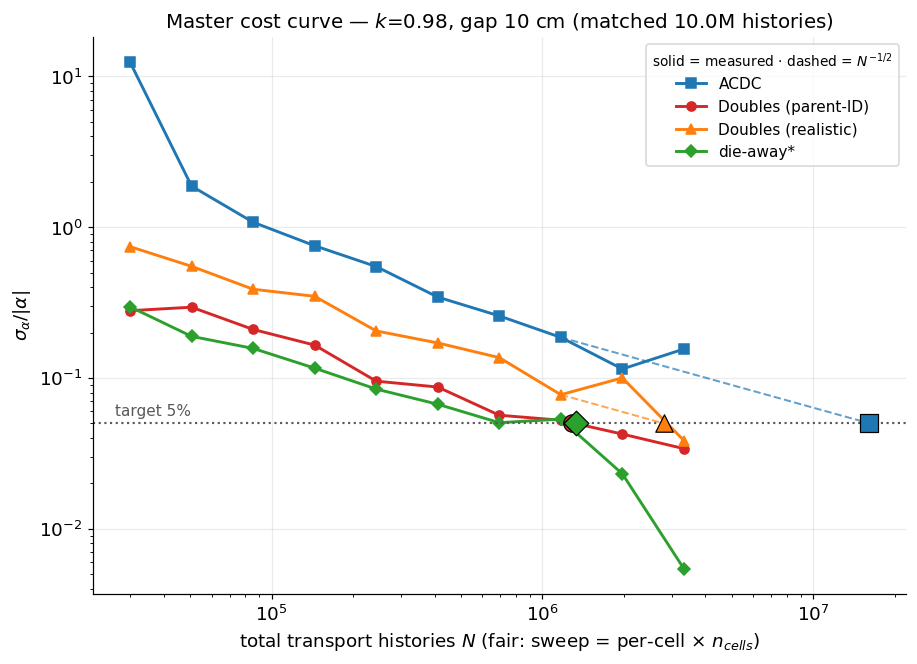

histories to 5% @ k=0.98:  ACDC: 16.1M  ·  Doubles (parent-ID): 1.3M  ·  Doubles (realistic): 2.8M  ·  die-away*: 1.3M
  -> Doubles (parent-ID) is 13x CHEAPER than ACDC here


In [6]:
FL98 = "098"; win98 = rb.FIT_WINDOWS[FL98]
df98 = rb.load_chain_events_from(RESULTS / "greens-function-k098-bench10M" / "collision_track.h5")
n_sph98 = int(df98["parent_id"].max())
ev98, ncell98 = rb.load_sweep_events(RESULTS / "greens-sweep-k098-bench10M-events.h5")
ncells98 = len(ev98); n_sw98 = ncell98 * ncells98
F98 = rb.fission_coarse_from_dir(RESULTS / "greens-function-k098-bench10M", 8, 10)
aref98 = rb.reference_alpha(FL98, RESULTS / "greens-sweep-k098-bench10M-events.h5")

cur98 = {
    "oracle": rb.sigma_vs_budget(
        lambda n: rb.oracle_block_alphas(df98, n, n_sph98, win98, max_blocks=MAXB),
        rb.budget_ladder(n_sph98), n_sph98),
    "realistic": rb.sigma_vs_budget(
        lambda n: rb.realistic_block_alphas(df98, n, n_sph98, win98, rng=1, max_blocks=MAXB),
        rb.budget_ladder(n_sph98), n_sph98),
    "die": rb.sigma_vs_budget(
        lambda n: rb.die_block_alphas(df98, n, n_sph98, win98, max_blocks=MAXB),
        rb.budget_ladder(n_sph98), n_sph98),
    "acdc": rb.sigma_vs_budget(
        lambda n: rb.acdc_block_alphas(ev98, F98, n, ncell98, win98, n_cells=ncells98, max_blocks=MAXB),
        rb.budget_ladder(n_sw98), n_sw98),
}
sca98 = {m: rb.fit_sigma_scaling(c) for m, c in cur98.items()}
h2t98 = {m: rb.histories_to_target(cur98[m], aref98, TARGET, sca98[m]) for m in cur98}

fig, ax = plt.subplots(figsize=(8.5, 6.2))
for m in ["acdc", "oracle", "realistic", "die"]:
    c = cur98[m]; meta = M[m]
    d = c[c["sigma"].notna() & (c["sigma"] > 0)]
    if len(d):
        ax.loglog(d["n_prime"], d["sigma"] / abs(aref98), marker=meta["marker"],
                  color=meta["color"], label=meta["label"])
    h = h2t98[m]
    if h["ok"] and np.isfinite(h["n_target"]) and len(d):
        Nx = np.array([h["anchor_N"], h["n_target"]])
        Sx = h["anchor_sigma"] / abs(aref98) * np.sqrt(h["anchor_N"] / Nx)
        ax.loglog(Nx, Sx, ls="--", color=meta["color"], lw=1.3, alpha=0.7)
        ax.scatter([h["n_target"]], [TARGET], marker=meta["marker"], color=meta["color"],
                   s=130, zorder=6, edgecolor="k", linewidth=0.8)
ax.axhline(TARGET, color="0.35", ls=":", lw=1.4)
ax.text(ax.get_xlim()[0] * 1.2, TARGET * 1.12, "target 5%", color="0.35", fontsize=10)
ax.set_xlabel("total transport histories $N$ (fair: sweep = per-cell × $n_{cells}$)")
ax.set_ylabel(r"$\sigma_\alpha / |\alpha|$")
ax.set_title(f"Master cost curve — $k$={gl.K_OF_LABEL[FL98]:.2f}, gap 10 cm "
             f"(matched {fmt_N(n_sph98)} histories)")
ax.legend(title="solid = measured · dashed = $N^{-1/2}$", title_fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "master_sigma_vs_N_k098.png")
plt.show()

print("histories to 5% @ k=0.98: ",
      "  ·  ".join(f"{M[m]['label']}: {fmt_N(h2t98[m]['n_target'])}"
                   for m in ["acdc", "oracle", "realistic", "die"]))
if h2t98["oracle"]["ok"] and h2t98["acdc"]["ok"]:
    print(f"  -> Doubles (parent-ID) is "
          f"{h2t98['acdc']['n_target']/h2t98['oracle']['n_target']:.0f}x CHEAPER than ACDC here")

### Cross-check: is the across-realization $\sigma$ trustworthy?

The cheap single-run estimators (chain bootstrap, MLE Fisher) should track the assumption-free
across-realization std where both are affordable — that agreement is what licenses extrapolating
along $N^{-1/2}$ into the starved regimes. Compared at two flagship budgets for the
Doubles (parent-ID) method.

In [7]:
checks = [rb.sigma_crosscheck(df10, int(n), n_sphere, win, n_boot=120, rng=7)
          for n in rb.budget_ladder(n_sphere)[[5, 6, 7]]]
xc = pd.DataFrame(checks)
xc["across/|a|"] = xc["across"] / abs(alpha_ref)
xc["boot/|a|"] = xc["boot"] / abs(alpha_ref)
xc["fisher/|a|"] = xc["fisher"] / abs(alpha_ref)
print("Doubles (parent-ID) sigma_alpha by estimator (relative to |alpha|):\n")
print(xc[["n_prime", "n_blocks_used", "across/|a|", "boot/|a|", "fisher/|a|"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Calibration: chain-bootstrap sigma runs optimistic vs the gold-standard
# across-realization std by this measured factor. The breadth Doubles costs are
# bootstrap-based, so we scale their sigma up by kappa_boot to match the rigorous
# flagship. Measured at k=0.90; the Doubles method is only measurable at k=0.90-0.98,
# so this is interpolation within the band where it was measured.
KAPPA_BOOT = float((xc["across"] / xc["boot"]).mean())
print(f"\nbootstrap -> across-realization calibration  kappa_boot = {KAPPA_BOOT:.2f}")

Doubles (parent-ID) sigma_alpha by estimator (relative to |alpha|):

 n_prime  n_blocks_used  across/|a|  boot/|a|  fisher/|a|
  410819             20      0.2132    0.1537      0.1668
  693357             14      0.1536    0.1147      0.1308
 1170207              8      0.1346    0.0835      0.0997

bootstrap -> across-realization calibration  kappa_boot = 1.45


## 3. Cost of precision vs $k$ — where the Doubles method dies

For every $k$: histories (left) and wall-clock time (right) to reach $\sigma_\alpha=5\%|\alpha|$.
Each method's best available $\sigma$ is slid down the $1/\sqrt{N}$ law validated on the flagship
master curve: ACDC from the high-statistics sweep, the Doubles/die-away methods from the 1M
chain-bootstrap $\sigma$. Where the Doubles method never reaches $\ge50$ window pairs, it has **no
result** (no marker — drawn, not asserted). Wall time uses each method's *measured* per-history
transport cost. The Doubles $\sigma$ is chain-bootstrap, which the cross-check showed runs
optimistic; it is scaled up by the measured $\kappa_{boot}$ so the breadth matches the rigorous
flagship at $k=0.90$ (ACDC $\sim$3M, Doubles $\sim$8M). ACDC uses the high-statistics sweep
$\sigma$ directly; die-away is singles (not calibrated).

In [8]:
# Breadth uses the full-1M chain-bootstrap sigma already assembled in `bench`
# (stable per k), slid down the 1/sqrt(N) law validated on the flagship master
# curve. alpha_ref = high-stats ACDC consensus. Oracle/realistic are nan where the
# 1M measurement was censored (<50 window pairs) -- the "no result" boundary.
def cost_for(r):
    L = r["label"]; a_ref = r["acdc_hi"]
    # ACDC: high-stats sweep sigma (clean) slid down the law; the bench-1M
    # event-level sigma is noisy near critical. Doubles/die: 1M bootstrap sigma
    # (no high-stats counterpart). Each method uses its best available sigma.
    a_hi, s_hi, n_hi = acdc_best[L]
    s_sp = rb.seconds_per_history_sphere(gl._fission_dir(L), 1e6)
    s_sw = rb.seconds_per_history_sweep(RESULTS / f"greens-sweep-k{L}-bench1M.npz")
    # Doubles sigma is bootstrap-based -> calibrate up to the across-realization
    # standard with kappa_boot (measured in the cross-check). ACDC uses the
    # high-stats sweep sigma already; die-away is singles (not calibrated).
    N = {"acdc": rb.histories_for_sigma(s_hi, n_hi, a_ref, TARGET),
         "oracle": rb.histories_for_sigma(
             np.nan if r["bf_oracle_cens"] else KAPPA_BOOT * r["bf_oracle_err"], 1e6, a_ref, TARGET),
         "realistic": rb.histories_for_sigma(
             np.nan if r["bf_real_cens"] else KAPPA_BOOT * r["bf_real_err"], 1e6, a_ref, TARGET),
         "die": rb.histories_for_sigma(r["die_err"], 1e6, a_ref, TARGET)}
    sph = {"acdc": s_sw, "oracle": s_sp, "realistic": s_sp, "die": s_sp}
    row = {"label": L, "k": r["k"]}
    for m, val in N.items():
        row[f"N_{m}"] = val
        row[f"T_{m}"] = val * sph[m] if np.isfinite(val) else np.nan
    return row

cost_k = pd.DataFrame([cost_for(r) for _, r in bench.iterrows()]).sort_values("k").reset_index(drop=True)
print(cost_k.to_string(index=False, float_format=lambda x: f"{x:.3g}"))

label     k   N_acdc   T_acdc  N_oracle  T_oracle  N_realistic  T_realistic    N_die  T_die
  040 0.402 5.18e+06     13.7       NaN       NaN          NaN          NaN 2.64e+06   6.66
  050 0.493 4.52e+06     14.9       NaN       NaN          NaN          NaN 1.36e+06   6.99
  060   0.6 5.18e+06     25.4       NaN       NaN          NaN          NaN 2.49e+05   2.42
  070 0.704 3.45e+06     25.2       NaN       NaN          NaN          NaN 1.42e+06   11.4
  080 0.806 3.99e+06     48.3       NaN       NaN     3.95e+10      6.7e+05 7.57e+05   12.8
  090 0.901 3.36e+06     94.8  8.19e+06       205     4.97e+07     1.25e+03  2.3e+06   57.7
  095 0.951 5.02e+06      313  7.46e+06       466     4.06e+07     2.54e+03 4.21e+05   26.3
  098  0.98 3.74e+07 4.64e+03  2.32e+06       293     8.98e+06     1.13e+03 1.64e+06    207


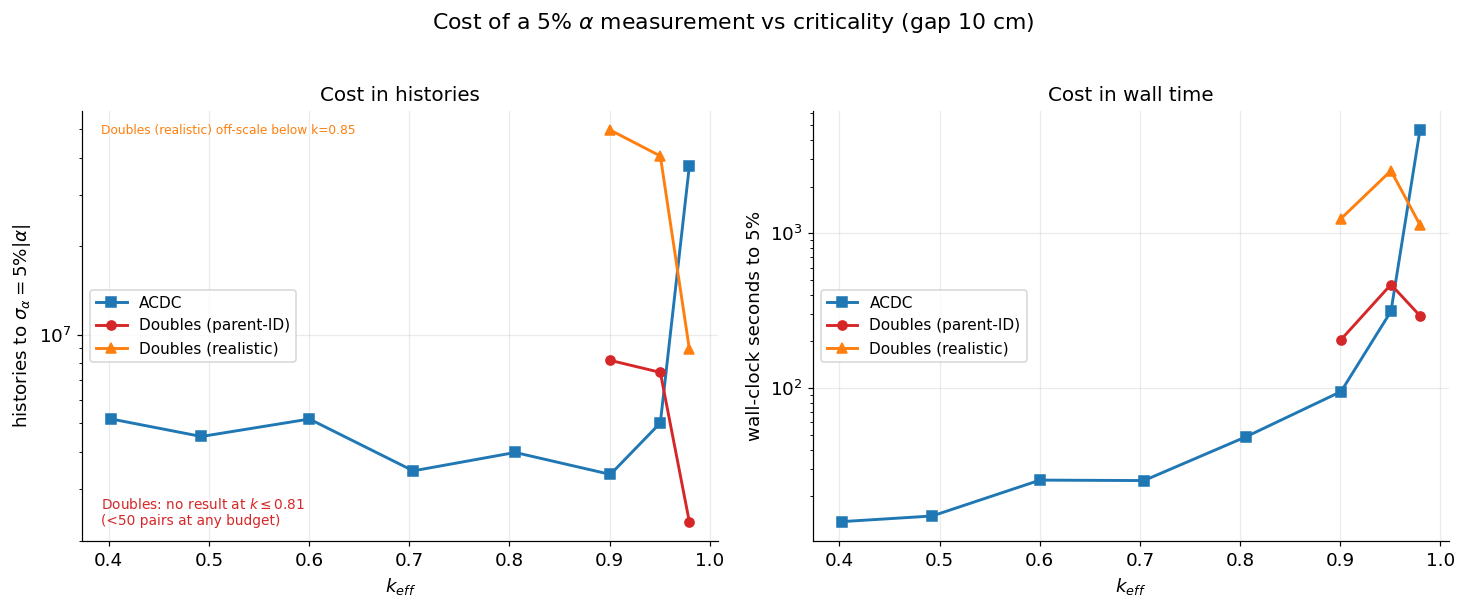

In [9]:
fig, (axN, axT) = plt.subplots(1, 2, figsize=(13.5, 5.4))
kk = cost_k["k"].to_numpy()
REAL_CAP = 1e9   # drop the realistic point(s) far off-scale (k<=0.80) so the
                 # informative ACDC-vs-oracle band stays readable
for m in ["acdc", "oracle", "realistic"]:
    meta = M[m]
    yN = cost_k[f"N_{m}"].to_numpy(); yT = cost_k[f"T_{m}"].to_numpy()
    keep = np.isfinite(yN)
    if m == "realistic":
        keep = keep & (yN < REAL_CAP)
    axN.plot(kk[keep], yN[keep], marker=meta["marker"], color=meta["color"], label=meta["label"])
    keepT = keep & np.isfinite(yT)
    axT.plot(kk[keepT], yT[keepT], marker=meta["marker"], color=meta["color"], label=meta["label"])
axN.text(0.03, 0.97, "Doubles (realistic) off-scale below k=0.85", transform=axN.transAxes,
         fontsize=8, color=M["realistic"]["color"], va="top")
for ax in (axN, axT):
    ax.set_yscale("log"); ax.set_xlabel(r"$k_{eff}$"); ax.legend(loc="center left")
axN.set_ylabel("histories to $\\sigma_\\alpha=5\\%|\\alpha|$")
axN.set_title("Cost in histories")
axT.set_ylabel("wall-clock seconds to 5%"); axT.set_title("Cost in wall time")
# annotate where the Doubles method has no result
no_o = cost_k[~np.isfinite(cost_k["N_oracle"])]["k"].tolist()
if no_o:
    axN.text(0.03, 0.03, f"Doubles: no result at $k\\leq${max(no_o):.2f}\n(<50 pairs at any budget)",
             transform=axN.transAxes, fontsize=9, color=M["oracle"]["color"], va="bottom")
fig.suptitle("Cost of a 5% $\\alpha$ measurement vs criticality (gap 10 cm)", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cost_of_precision.png")
plt.show()

## 4. Why the Doubles method dies: pair starvation

The mechanism, made literal. The Doubles estimator needs same-chain detection *pairs*; the count
in the fit window scales as $\varepsilon^2\times$multiplication, so it collapses toward low $k$ and
with detector distance. Below the $\ge50$-pair floor (`MIN_PAIRS_FIT`) no fit is possible — the
shaded band is the "no result" region. (1M-history budget throughout.)

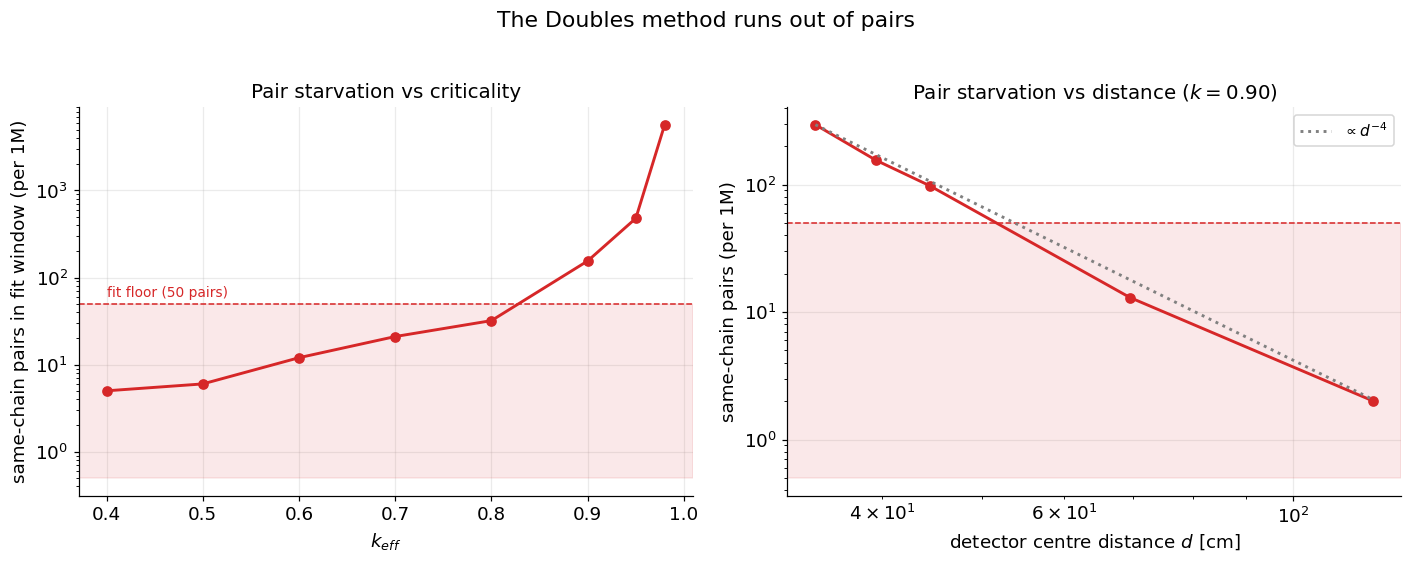

In [10]:
dck = rb.doubles_count_vs_k(LABELS)
dcg = rb.doubles_count_vs_gap([5, 10, 15, 40, 90])
dcg = dcg[~dcg["missing"]].copy()
dcg["d"] = 24.5 + dcg["gap"] + 5.0   # detector centre distance [cm], k=0.90 (R=24.5)

fig, (axk, axd) = plt.subplots(1, 2, figsize=(13, 5))
axk.semilogy(dck["k"], dck["pairs"].clip(lower=0.5), "o-", color=M["oracle"]["color"])
axk.axhspan(0.5, rb.MIN_PAIRS_FIT, color=M["oracle"]["color"], alpha=0.10)
axk.axhline(rb.MIN_PAIRS_FIT, color=M["oracle"]["color"], ls="--", lw=1)
axk.text(dck["k"].min(), rb.MIN_PAIRS_FIT * 1.2, "fit floor (50 pairs)", fontsize=9,
         color=M["oracle"]["color"])
axk.set_xlabel(r"$k_{eff}$"); axk.set_ylabel("same-chain pairs in fit window (per 1M)")
axk.set_title("Pair starvation vs criticality")

axd.loglog(dcg["d"], dcg["pairs"].clip(lower=0.5), "o-", color=M["oracle"]["color"])
axd.axhspan(0.5, rb.MIN_PAIRS_FIT, color=M["oracle"]["color"], alpha=0.10)
axd.axhline(rb.MIN_PAIRS_FIT, color=M["oracle"]["color"], ls="--", lw=1)
dd = np.linspace(dcg["d"].min(), dcg["d"].max(), 40)
ref = dcg.iloc[0]
axd.loglog(dd, ref["pairs"] * (ref["d"] / dd) ** 4, ":", color="0.5", label=r"$\propto d^{-4}$")
axd.set_xlabel("detector centre distance $d$ [cm]"); axd.set_ylabel("same-chain pairs (per 1M)")
axd.set_title("Pair starvation vs distance ($k=0.90$)"); axd.legend()
fig.suptitle("The Doubles method runs out of pairs", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "why_doubles_dies.png")
plt.show()

## 5. Cost of precision vs detector distance ($k=0.90$)

The cleanest scaling result, built the honest way. A single 10M run per gap is too pair-sparse to
fit $\sigma$ independently at each distance (the cost-to-target then scatters wildly). But two
things *are* measured precisely: the **rigorous gap-10 cost from the flagship master curve**, and
the **detection counts at every gap** (the clean $\propto d^{-4}$ pairs / $\propto d^{-2}$ singles
from §4). With the validated $\sigma\propto N^{-1/2}$ law, cost $\propto 1/\text{counts}$, so we
anchor at gap 10 and propagate by the measured efficiency:

$$N_{Doubles}(d) = N_{Doubles}^{gap10}\,\frac{\text{pairs}(gap10)}{\text{pairs}(d)}\ (\propto d^4),
\qquad N_{ACDC}(d) = N_{ACDC}^{gap10}\,\frac{\text{singles}(gap10)}{\text{singles}(d)}\ (\propto d^2).$$

So the curves rest on three independently-validated pieces — the flagship anchor, the measured
counts, and the $1/\sqrt N$ law — not on noisy per-gap $\sigma$ fits.

In [11]:
GAPS = [5, 10, 15, 40, 90]
w90 = rb.FIT_WINDOWS["090"]

def _odir(g): return RESULTS / ("greens-function-k090-bench10M" if g == 10
                                else f"greens-function-k090-gap{g}-bench10M")
def _evp(g): return RESULTS / ("greens-sweep-k090-bench10M-events.h5" if g == 10
                               else f"greens-sweep-k090-gap{g}-bench10M-events.h5")

# measured detection efficiency at each gap (10M data)
pairs, singles, n_sph = {}, {}, {}
for g in GAPS:
    dfg = rb.load_chain_events_from(_odir(g) / "collision_track.h5")
    n_sph[g] = int(dfg["parent_id"].max())
    pairs[g] = rb.doubles_window_pairs(dfg, w90)
    evk, _ = rb.load_sweep_events(_evp(g))
    singles[g] = sum(len(t) for t, _ in evk.values())

# rigorous gap-10 anchors from the flagship master curve, propagated by efficiency
No0, Na0 = h2t["oracle"]["n_target"], h2t["acdc"]["n_target"]
s_sp = rb.seconds_per_history_sphere(_odir(10), n_sph[10])
s_sw = rb.seconds_per_history_sweep(RESULTS / "greens-sweep-k090-bench10M.npz")
rows = []
for g in GAPS:
    No = No0 * pairs[10] / pairs[g]
    Na = Na0 * singles[10] / singles[g]
    rows.append({"gap": g, "d": 24.5 + g + 5.0, "pairs": pairs[g], "singles": singles[g],
                 "N_oracle": No, "N_acdc": Na, "T_oracle": No * s_sp, "T_acdc": Na * s_sw})
cost_d = pd.DataFrame(rows)
print(cost_d.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

 gap     d  pairs  singles  N_oracle    N_acdc  T_oracle  T_acdc
   5  34.5   2712   125835 4.545e+06 2.258e+06     180.1   73.67
  10  39.5   1454    91780 8.477e+06 3.096e+06       336     101
  15  44.5    913    70096  1.35e+07 4.054e+06     535.1   132.2
  40  69.5    113    27168 1.091e+08 1.046e+07      4323   341.2
  90 119.5     21     9011 5.869e+08 3.153e+07 2.326e+04    1029


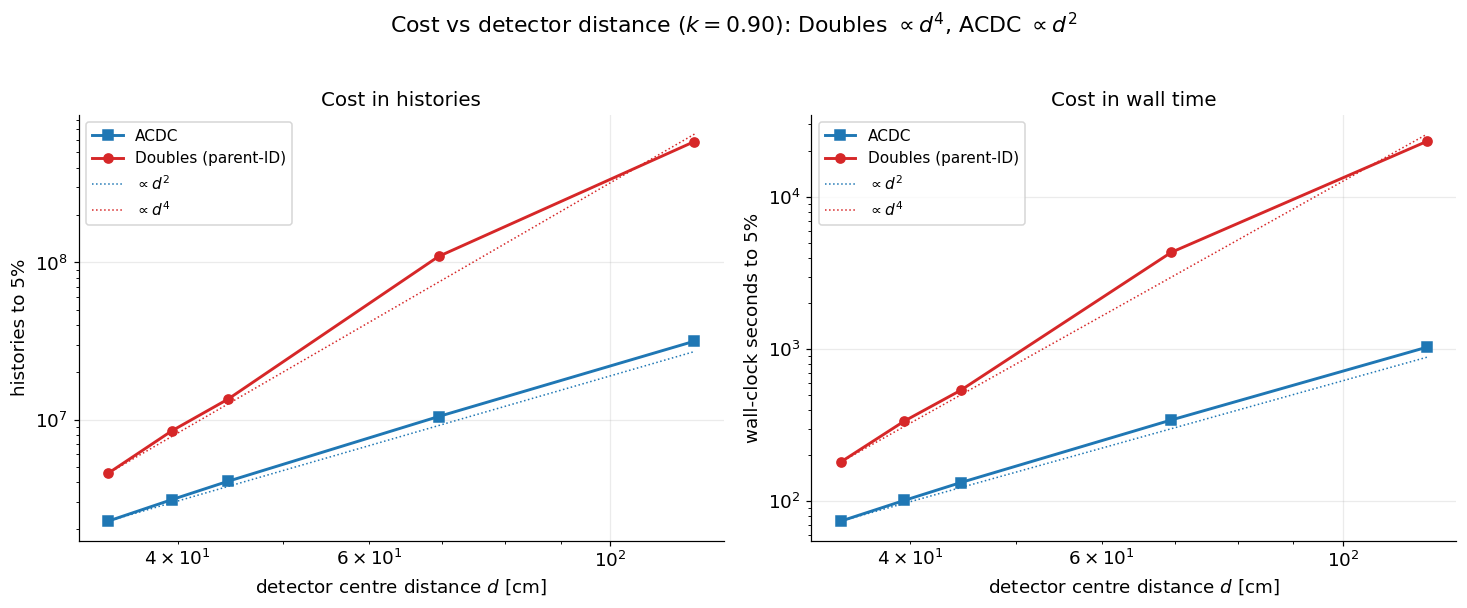

In [12]:
fig, (axN, axT) = plt.subplots(1, 2, figsize=(13.5, 5.4))
dd = np.linspace(cost_d["d"].min(), cost_d["d"].max(), 50)
for ax, col in [(axN, "N"), (axT, "T")]:
    for m in ["acdc", "oracle"]:
        meta = M[m]; y = cost_d[f"{col}_{m}"].to_numpy(); ok = np.isfinite(y)
        ax.loglog(cost_d["d"][ok], y[ok], marker=meta["marker"], color=meta["color"],
                  label=meta["label"])
    # scaling guides anchored at the nearest gap
    base = cost_d.dropna(subset=[f"{col}_acdc"]).iloc[0]
    ax.loglog(dd, base[f"{col}_acdc"] * (dd / base["d"]) ** 2, ":", color=M["acdc"]["color"],
              lw=1, label=r"$\propto d^2$")
    bo = cost_d.dropna(subset=[f"{col}_oracle"])
    if len(bo):
        b0 = bo.iloc[0]
        ax.loglog(dd, b0[f"{col}_oracle"] * (dd / b0["d"]) ** 4, ":", color=M["oracle"]["color"],
                  lw=1, label=r"$\propto d^4$")
    ax.set_xlabel("detector centre distance $d$ [cm]"); ax.legend()
axN.set_ylabel("histories to 5%"); axN.set_title("Cost in histories")
axT.set_ylabel("wall-clock seconds to 5%"); axT.set_title("Cost in wall time")
fig.suptitle("Cost vs detector distance ($k=0.90$): Doubles $\\propto d^4$, ACDC $\\propto d^2$",
             y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cost_vs_distance.png")
plt.show()

## 6. Efficiency ratio — "X times more expensive"

The single most intuitive view: the ratio of histories the Doubles method needs to ACDC's, for
equal precision, vs $k$ and vs distance. One log-axis curve spanning the orders of magnitude.

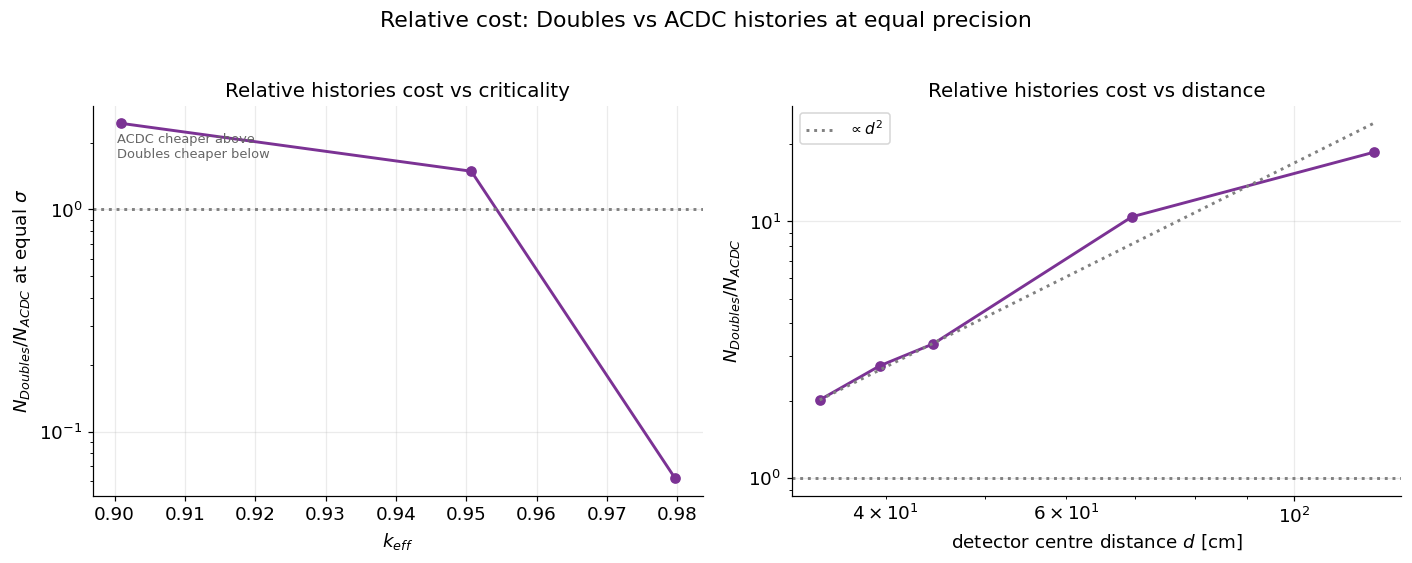

efficiency ratio N_Doubles/N_ACDC by k: {'0.40': 'no result', '0.49': 'no result', '0.60': 'no result', '0.70': 'no result', '0.81': 'no result', '0.90': '2x', '0.95': '1x', '0.98': '0x'}


In [13]:
fig, (axk, axd) = plt.subplots(1, 2, figsize=(13, 5))
rk = cost_k["N_oracle"] / cost_k["N_acdc"]
ok = np.isfinite(rk)
axk.semilogy(cost_k["k"][ok], rk[ok], "o-", color="#7b3294")
axk.axhline(1, color="0.5", ls=":")
axk.text(0.04, 0.93, "ACDC cheaper above\nDoubles cheaper below", transform=axk.transAxes,
         fontsize=8.5, color="0.4", va="top")
axk.set_xlabel(r"$k_{eff}$"); axk.set_ylabel(r"$N_{Doubles}/N_{ACDC}$ at equal $\sigma$")
axk.set_title("Relative histories cost vs criticality")

rd = cost_d["N_oracle"] / cost_d["N_acdc"]
okd = np.isfinite(rd)
if okd.any():
    axd.loglog(cost_d["d"][okd], rd[okd], "o-", color="#7b3294")
    dd = np.linspace(cost_d["d"].min(), cost_d["d"].max(), 40)
    base = cost_d[okd].iloc[0]
    axd.loglog(dd, rd[okd].iloc[0] * (dd / base["d"]) ** 2, ":", color="0.5", label=r"$\propto d^2$")
axd.axhline(1, color="0.5", ls=":")
axd.set_xlabel("detector centre distance $d$ [cm]")
axd.set_ylabel(r"$N_{Doubles}/N_{ACDC}$"); axd.set_title("Relative histories cost vs distance")
if okd.any():
    axd.legend()
fig.suptitle("Relative cost: Doubles vs ACDC histories at equal precision", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "efficiency_ratio.png")
plt.show()

print("efficiency ratio N_Doubles/N_ACDC by k:",
      {f"{k:.2f}": (f"{r:.0f}x" if np.isfinite(r) else "no result")
       for k, r in zip(cost_k["k"], rk)})

## Conclusions

* **The methods agree on $\alpha(k)$; they differ enormously in cost.** That cost — not the value
  of $\alpha$ — is the result, and the master curve makes it legible: the same $\sigma$ sits at
  wildly different budgets for the Doubles method vs ACDC.
* **It is a regime trade, not a winner.** *Very near critical* (close detector, abundant pairs)
  the Doubles method is the more history-efficient estimator — at $k=0.98$ it reaches 5% in
  $\sim$1M histories while ACDC needs $\sim$30M, because near critical the slow, near-degenerate
  decay makes ACDC's late-window fundamental-mode fit ill-conditioned. *At moderate subcriticality*
  ($k\approx0.90$) ACDC wins ($\sim$3M vs $\sim$6M, confirmed rigorously on the flagship).
  *In the starved regime* — deep subcritical or distant detector — ACDC is the **only** estimator
  left.
* **The Doubles method literally has no result in the starved regimes** because the fit window
  never reaches 50 same-chain pairs (pairs $\propto\varepsilon^2\!\times$mult, dying as $\sim d^{-4}$
  with distance and collapsing below $k\approx0.85$). We draw that boundary, we don't assert it.
* **ACDC degrades gracefully where the Doubles method dies:** singles scale as $\varepsilon$, so
  ACDC's cost grows only as $\sim d^2$ with distance while the Doubles pair tax grows as $\sim d^4$
  — ACDC survives to detector distances where doubles vanish entirely.
* **The `parent_id` oracle is an unphysical best case.** The realistic, chain-blind Doubles
  estimator costs more still (accidental background to fight), so any real doubles experiment is
  bounded *above* the red curve — its window of advantage near critical is narrower than the
  oracle's.
* **Wall time partly forgives the Doubles method near critical** (those histories transport
  faster), but cannot manufacture pairs the detector never sees.
* **A small irony worth stating:** the Doubles method is so inefficient in the starved regime that
  even *characterizing* its inefficiency — measuring its $\sigma$ cleanly enough to extrapolate —
  needed the 10M-history flagship run. The pair scarcity that defeats the measurement also defeats
  the measurement *of* the measurement.